
### ¿Que se hace en estos casos?. 

Recordando que la red neuronal fue construida por nosotros. Tenemos distintos caminos para mejorar la convergencia.

### Cambiar la función de interés.
Por lo general, esta es fija y no se puede cambiar. En este ejemplo, manteniendo la configuración de la red neuronal fija, Procuraremos funciónes que compartan rango con la sigmoide.

Consideremos ahora la función de distribución de la distribución normal estándar

$$
    F(x)=\dfrac{1}{\sqrt{2\pi}}\int_{-\infty}^x \exp\left(\dfrac{x^2}{2}\right)\mathrm{d}x.
$$

Sabemos que por definición $0\leq F(x)\leq 1,\forall x$ entonces la red deberia aproximarla mejor.

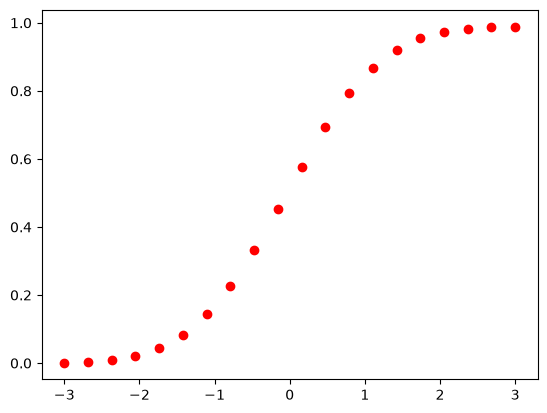

In [4]:
from neuralnetworks.nn import descent_gradent, sigmoid
import numpy as np
import matplotlib.pyplot as plt


def integ(x):
    c = 1/np.sqrt(2*np.pi)
    y = c * np.exp(-0.5 * x ** 2)
    return y


def goal(interval: tuple, N=100, func = integ):
    a,b = interval
    part = np.linspace(a,b, N)
    int_v = integ(part) * (b - a)
    return int_v.mean()


def distf(x):
    return goal((-10, x))

train_x = np.linspace(-3, 3, 20)
train_y = np.array([distf(x) for x in train_x])

plt.plot(train_x, train_y, "ro", label="Datos Entrenamienot")


# Ajuste con Red Neuronal

0 0.005088473783324006
Error 0.027619225888203654
Mejores parametros
c= 0.9879951053412268
w= 0.6405020157086521
b= 0.19218163426521348


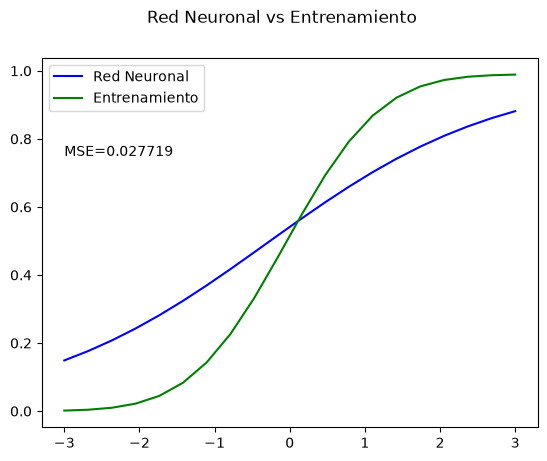

In [12]:
# Construimos la red neuronal. 
def model(x, theta, func=sigmoid):
    # Se ve sencilla porque es una neurona.
    c = theta[0]
    w = theta[1]
    b = theta[2]
    v = w * x + b
    y = c * func(v)
    return y


def mse_nn(y, x, func, pars):
    pred = [func(t, pars) for t in x]
    diff = (y - pred) ** 2
    error = diff.mean()
    return error



def error_learn(theta):
    y = mse_nn(y = train_y, x = train_x, func=model, pars=theta)
    return y


epsilon = 0.001
theta_0= [0.1,0.1,0.1]

param_fit = descent_gradent(error_learn, theta_0, epsilon)

print("Mejores parametros")
print("c=", param_fit[0])
print("w=", param_fit[1])
print("b=", param_fit[2])

def fitmodel(v):
    return model(v, param_fit)

predicted = [fitmodel(x) for x in train_x]
fig, ax = plt.subplots()
ax.plot(train_x, predicted, color="blue", label="Red Neuronal")
ax.plot(train_x, train_y, color="green", label="Entrenamiento")
ax.annotate(text=f"MSE={error_learn(param_fit):2f}", xy=[-3,0.75])
fig.suptitle("Red Neuronal vs Entrenamiento")
ax.legend()

# Grafica del Error

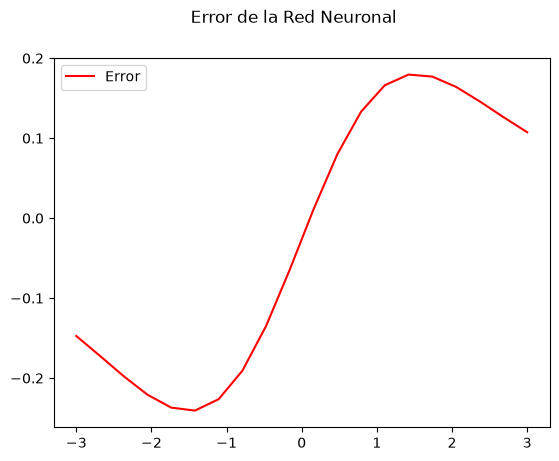

In [13]:
fig, ax = plt.subplots()
ax.plot(train_x, train_y-np.array(predicted), color="red", label="Error")
fig.suptitle("Error de la Red Neuronal")
ax.legend()